#  FYP: Dengue Detection (Raman): PCA+LDA
**Steps:**
1. Libraries
2. Data Load + Preprocessing (duplicates remove)
3. EDA (short)
4. Patient-wise Cross-Validation setup
5. Scaling
6. PCA
7. Class Balancing (SMOTE)
8. LDA
9. Model Evaluation (best n_components + final results)
10. Final Model Save
11. prediction on new csv



#  Step 1: Libraries

In [1]:
!pip -q install imbalanced-learn

In [2]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             precision_score, f1_score, roc_curve, auc)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

SEED = 42
DATA_FILE = 'dengue_preprocessed.csv'    # File name
print(' Libraries ready!')

 Libraries ready!


#  Step 2: Data Load + Preprocessing

In [3]:
if IN_COLAB:
    print(f'📁 {DATA_FILE} upload dataset...')
    files.upload()

df = pd.read_csv(DATA_FILE)
wn_cols = [c for c in df.columns if c.startswith('wn_')]

print('Shape            :', df.shape)
print('Spectral columns :', len(wn_cols))
print('Missing values   :', df[wn_cols].isnull().sum().sum())
print('Duplicate spectra:', df.duplicated(subset=wn_cols).sum())

# 1) if there are missing values fill them using median
df[wn_cols] = df[wn_cols].fillna(df[wn_cols].median())

# 2) Duplicate spectra remove
n_before = len(df)
df = df.drop_duplicates(subset=wn_cols).reset_index(drop=True)
print(f'\n Duplicates removed: {n_before - len(df)}  ({n_before} → {len(df)} rows)')

X = df[wn_cols].values.astype(float)
y = df['label'].values.astype(int)
groups = df['patient_id'].values      # All samples of each patient will be kept together.

print(f'\nDengue : {(y==1).sum()}  |  Healthy : {(y==0).sum()}')
print(f'Patients: {len(np.unique(groups))}  (Dengue={df[df.label==1].patient_id.nunique()}, Healthy={df[df.label==0].patient_id.nunique()})')

📁 dengue_preprocessed.csv upload dataset...


Saving dengue_preprocessed.csv to dengue_preprocessed.csv
Shape            : (760, 668)
Spectral columns : 666
Missing values   : 0
Duplicate spectra: 138

 Duplicates removed: 138  (760 → 622 rows)

Dengue : 340  |  Healthy : 282
Patients: 38  (Dengue=23, Healthy=15)


#  Step 3: EDA

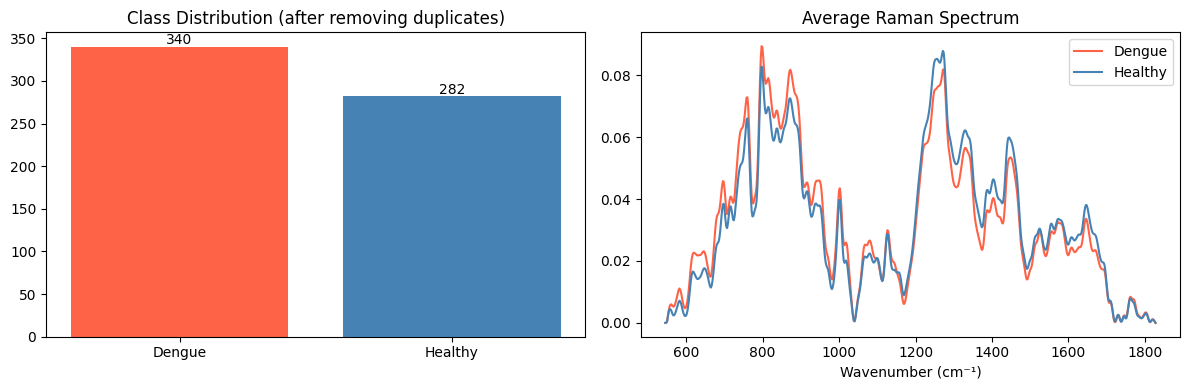

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

counts = pd.Series(y).map({0: 'Healthy', 1: 'Dengue'}).value_counts()
axes[0].bar(counts.index, counts.values, color=['tomato', 'steelblue'])
axes[0].set_title('Class Distribution (after removing duplicates)')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 3, str(v), ha='center')

wavenumbers = [float(c[3:]) for c in wn_cols]
axes[1].plot(wavenumbers, X[y == 1].mean(axis=0), color='tomato', label='Dengue')
axes[1].plot(wavenumbers, X[y == 0].mean(axis=0), color='steelblue', label='Healthy')
axes[1].set_title('Average Raman Spectrum'); axes[1].set_xlabel('Wavenumber (cm⁻¹)'); axes[1].legend()
plt.tight_layout(); plt.show()

#  Step 4: Patient-wise Cross-Validation (On All dataset)


In [5]:
N_OUTER = 8
cv = StratifiedGroupKFold(n_splits=N_OUTER, shuffle=True, random_state=SEED)

for k, (tr, te) in enumerate(cv.split(X, y, groups), 1):
    common = len(set(groups[tr]) & set(groups[te]))
    print(f'Fold {k}: train={len(tr):3d} | test={len(te):3d} | test patients={len(np.unique(groups[te]))} | common patients={common}')

Fold 1: train=546 | test= 76 | test patients=5 | common patients=0
Fold 2: train=558 | test= 64 | test patients=4 | common patients=0
Fold 3: train=556 | test= 66 | test patients=4 | common patients=0
Fold 4: train=533 | test= 89 | test patients=5 | common patients=0
Fold 5: train=534 | test= 88 | test patients=5 | common patients=0
Fold 6: train=547 | test= 75 | test patients=5 | common patients=0
Fold 7: train=537 | test= 85 | test patients=5 | common patients=0
Fold 8: train=543 | test= 79 | test patients=5 | common patients=0


#  Step 5: Scaling

In [6]:
scaler = StandardScaler()
print(' StandardScaler ready (In each fold, only the train will fit.)')

 StandardScaler ready (In each fold, only the train will fit.)


#  Step 6: PCA

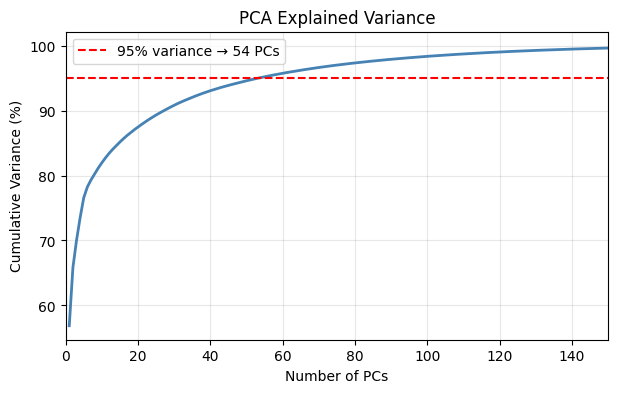

In [7]:
# only to see variance (not for model)
pca_full = PCA().fit(StandardScaler().fit_transform(X))
cumvar = np.cumsum(pca_full.explained_variance_ratio_)
n_95 = int(np.argmax(cumvar >= 0.95) + 1)

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cumvar) + 1), cumvar * 100, color='steelblue', lw=2)
plt.axhline(95, color='red', ls='--', label=f'95% variance → {n_95} PCs')
plt.xlim(0, 150); plt.xlabel('Number of PCs'); plt.ylabel('Cumulative Variance (%)')
plt.title('PCA Explained Variance'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

pca = PCA(random_state=SEED)   # n_components will be selected using cross-validation in Step 9

#  Step 7: Class Balancing (SMOTE)
Synthetic samples of the healthy class are generated only on the training data. Below is an example of one fold showing what happens before and after balancing.

In [8]:
smote = SMOTE(random_state=SEED)

tr, te = next(cv.split(X, y, groups))          # Demo: first training data of fold
Xd = StandardScaler().fit_transform(X[tr])
Xd = PCA(n_components=20, random_state=SEED).fit_transform(Xd)
Xd_bal, yd_bal = SMOTE(random_state=SEED).fit_resample(Xd, y[tr])

print(f'Fold 1 train — Before     : Dengue={(y[tr]==1).sum()}, Healthy={(y[tr]==0).sum()}')
print(f'Fold 1 train — After      : Dengue={(yd_bal==1).sum()}, Healthy={(yd_bal==0).sum()}')
print('(The test fold is not touched)')


Fold 1 train — Before     : Dengue=283, Healthy=263
Fold 1 train — After      : Dengue=283, Healthy=283
(The test fold is not touched)


#  Step 8: LDA

In [9]:
lda = LinearDiscriminantAnalysis()
print('LDA ready')

LDA ready


#  Step 9: Model Evaluation
Steps 5–8 are combined into a pipeline: Scaler → PCA → SMOTE → LDA.

9.1 :For each n_components, compute the CV score and choose the best (for the final model).

9.2 : Final honest result (nested CV, repeated across 5 different fold-splits). Since the dataset is small, one split’s numbers may vary slightly, but the average of 5 repeats is more reliable.

9.3 : Patient-level result and misclassified patients.

In [10]:
pipe = Pipeline([('scaler', scaler), ('pca', pca), ('smote', smote), ('lda', lda)])
N_LIST = [5, 10, 20, 30, 50, 80, 100]

# 9.1: CV score for each n_components
cv_results = {}
print('n_PCs | Accuracy | Balanced Acc | Sensitivity | Specificity')
print('-' * 62)
for n in N_LIST:
    pipe.set_params(pca__n_components=n)
    pred = cross_val_predict(pipe, X, y, cv=cv, groups=groups)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    cv_results[n] = (accuracy_score(y, pred) * 100, balanced_accuracy_score(y, pred) * 100,
                     tp / (tp + fn) * 100, tn / (tn + fp) * 100)
    a, b, s, p = cv_results[n]
    print(f'{n:5d} | {a:7.2f}% | {b:11.2f}% | {s:10.2f}% | {p:10.2f}%')

best_n = max(cv_results, key=lambda k: cv_results[k][1])
print('-' * 62)
print(f' Best n_components = {best_n}')

n_PCs | Accuracy | Balanced Acc | Sensitivity | Specificity
--------------------------------------------------------------
    5 |   83.12% |       83.77% |      76.76% |      90.78%
   10 |   85.85% |       86.54% |      79.12% |      93.97%
   20 |   93.89% |       94.02% |      92.65% |      95.39%
   30 |   94.69% |       94.72% |      94.41% |      95.04%
   50 |   96.14% |       96.05% |      97.06% |      95.04%
   80 |   96.62% |       96.49% |      97.94% |      95.04%
  100 |   97.59% |       97.52% |      98.24% |      96.81%
--------------------------------------------------------------
 Best n_components = 100


In [14]:
#9.2: Nested CV, 5 repeats (n_components is selected within each fold only from the training patients).SEEDS = [42, 7, 123, 2024, 99]
SEEDS = [42, 7, 123, 2024, 99]
rows = []

for s in SEEDS:
    outer = StratifiedGroupKFold(n_splits=N_OUTER, shuffle=True, random_state=s)
    y_pred = np.zeros(len(y), dtype=int)
    y_prob = np.zeros(len(y))

    for tr, te in outer.split(X, y, groups):
        inner = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=s)
        gs = GridSearchCV(pipe, {'pca__n_components': N_LIST}, cv=inner,
                          scoring='balanced_accuracy', n_jobs=-1)
        gs.fit(X[tr], y[tr], groups=groups[tr])
        y_pred[te] = gs.predict(X[te])
        y_prob[te] = gs.predict_proba(X[te])[:, 1]

    # Patient-level: the average probability of all spectra belonging to a single patient.
    pat = pd.DataFrame({'patient': groups, 'y': y, 'p': y_prob}).groupby('patient').agg(y=('y', 'first'), p=('p', 'mean'))
    pat_pred = (pat.p >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(y, y_pred).ravel()
    fpr, tpr, _ = roc_curve(y, y_prob)
    rows.append({'Accuracy %': accuracy_score(y, y_pred) * 100,
                 'Balanced Acc %': balanced_accuracy_score(y, y_pred) * 100,
                 'Sensitivity %': tp / (tp + fn) * 100,
                 'Specificity %': tn / (tn + fp) * 100,
                 'AUC': auc(fpr, tpr),
                 'Patient Acc %': (pat_pred == pat.y).mean() * 100})
    if s == SEEDS[0]:
        y_pred0, y_prob0, fpr0, tpr0, pat0 = y_pred.copy(), y_prob.copy(), fpr, tpr, pat.copy()
    print(f'seed {s}: done')

res = pd.DataFrame(rows, index=SEEDS)
print('\n' + '=' * 62)
print('   FINAL RESULTS (all patients, nested CV, 5 repeats)')
print('=' * 62)
print(res.round(2).to_string())
print('-' * 62)
print('Mean :', res.mean().round(2).to_dict())
print('Std  :', res.std().round(2).to_dict())
print('=' * 62)
print('Paper: Acc=96.50% | Sens=93.44% | Spec=100%')

seed 42: done
seed 7: done
seed 123: done
seed 2024: done
seed 99: done

   FINAL RESULTS (all patients, nested CV, 5 repeats)
      Accuracy %  Balanced Acc %  Sensitivity %  Specificity %   AUC  Patient Acc %
42         97.27           97.20          97.94          96.45  0.99          97.37
7          96.46           96.22          98.82          93.62  0.99          97.37
123        96.30           96.22          97.06          95.39  0.99          97.37
2024       96.46           96.28          98.24          94.33  0.99          97.37
99         95.34           95.28          95.88          94.68  0.99          97.37
--------------------------------------------------------------
Mean : {'Accuracy %': 96.37, 'Balanced Acc %': 96.24, 'Sensitivity %': 97.59, 'Specificity %': 94.89, 'AUC': 0.99, 'Patient Acc %': 97.37}
Std  : {'Accuracy %': 0.69, 'Balanced Acc %': 0.68, 'Sensitivity %': 1.15, 'Specificity %': 1.08, 'AUC': 0.0, 'Patient Acc %': 0.0}
Paper: Acc=96.50% | Sens=93.44% | S

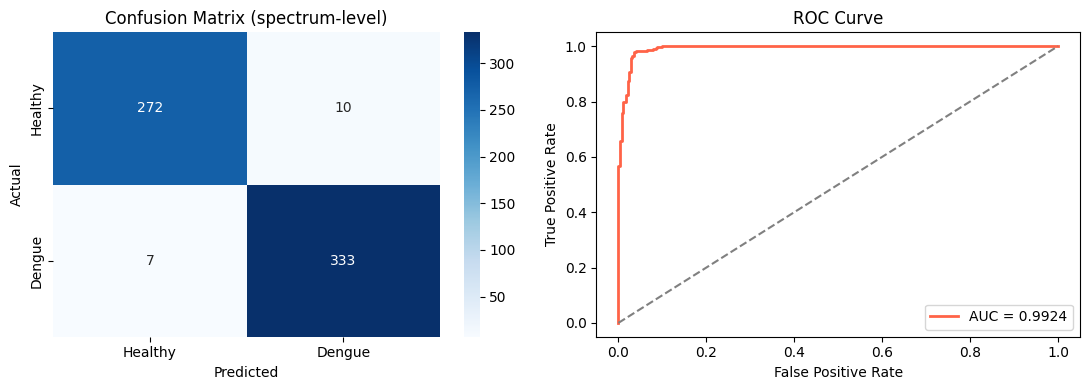

Patient-level accuracy: 97.37%  (37/38 patients correct)
Patients who are misclassified:
            actual  mean_dengue_prob  predicted
patient                                        
Healthy 15       0             0.602          1


In [15]:
# Plots (predictions from the first seed)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(confusion_matrix(y, y_pred0), annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Healthy', 'Dengue'], yticklabels=['Healthy', 'Dengue'])
axes[0].set_title('Confusion Matrix (spectrum-level)'); axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')
axes[1].plot(fpr0, tpr0, color='tomato', lw=2, label=f'AUC = {auc(fpr0, tpr0):.4f}')
axes[1].plot([0, 1], [0, 1], 'gray', ls='--')
axes[1].set_title('ROC Curve'); axes[1].set_xlabel('False Positive Rate'); axes[1].set_ylabel('True Positive Rate')
axes[1].legend()
plt.tight_layout(); plt.show()

# 9.3: Patient-level which patients are incorrect.
pat0['predicted'] = (pat0.p >= 0.5).astype(int)
wrong = pat0[pat0.predicted != pat0.y]
print(f'Patient-level accuracy: {(pat0.predicted == pat0.y).mean()*100:.2f}%  ({len(pat0) - len(wrong)}/{len(pat0)} patients correct)')
print('Patients who are misclassified:')
print(wrong.rename(columns={'y': 'actual', 'p': 'mean_dengue_prob'}).round(3).to_string())

#  Step 10: Final Model Save
For deployment, the model is trained on the entire dataset (using best_n). The saved model contains only scaler → pca → lda (SMOTE was used only during training).

In [16]:
pipe.set_params(pca__n_components=best_n)
pipe.fit(X, y)

model_package = {'scaler': pipe.named_steps['scaler'],
                 'pca'   : pipe.named_steps['pca'],
                 'lda'   : pipe.named_steps['lda'],
                 'wn_cols': wn_cols}
with open('dengue_model.pkl', 'wb') as f:
    pickle.dump(model_package, f)

print(f'Model saved: dengue_model.pkl  (n_components={best_n})')
if IN_COLAB:
    files.download('dengue_model.pkl')

Model saved: dengue_model.pkl  (n_components=100)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#  Step 11: prediction on new csv

In [17]:
def predict_from_csv(csv_path):
    new = pd.read_csv(csv_path)
    missing = [c for c in wn_cols if c not in new.columns]
    if missing:
        print(f'{len(missing)} columns are missing (required {len(wn_cols)})')
        return None
    Xn = new[wn_cols].values.astype(float)
    Xn = model_package['pca'].transform(model_package['scaler'].transform(Xn))
    prob = model_package['lda'].predict_proba(Xn)
    out = pd.DataFrame({
        'patient_id'   : new['patient_id'] if 'patient_id' in new.columns else range(len(new)),
        'prediction'   : np.where(prob[:, 1] >= 0.5, 'Dengue', 'Healthy'),
        'dengue_prob_%': (prob[:, 1] * 100).round(2),
        'confidence_%' : (prob.max(axis=1) * 100).round(2),
    })
    return out

if IN_COLAB:
    print('upload your csv...')
    up = files.upload()
    res_new = predict_from_csv(list(up.keys())[0])
    if res_new is not None:
        print(res_new.to_string(index=False))
        res_new.to_csv('predictions_output.csv', index=False)
        files.download('predictions_output.csv')

upload your csv...


Saving dummy_unseen_dengue.csv to dummy_unseen_dengue.csv
      patient_id prediction  dengue_prob_%  confidence_%
DUMMY_DENGUE_999     Dengue          100.0         100.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>